# Uniformity of search: does covering the arena evenly go with more trials?

`occupancy_nose.ipynb` describes *where* the nose is while searching. This notebook reduces each session's map to one number, how **evenly** the search time is spread, and asks whether sessions with more trials are the ones with more even coverage.

**Uniformity index.** The normalized Shannon entropy of the session's search-time occupancy:

$$U = \frac{-\sum_i p_i \log p_i}{\log N}$$

where $p_i$ is the share of search time the nose spends in bin $i$ and $N$ is the number of bins. $U = 1$ when every bin gets the same time; it falls toward 0 as time piles up in fewer bins. It is computed two ways:

- **within the target grid** (the 3 x 9 cells, 12 x 36 bins): how evenly the mouse covers the places a target can be. This is the main measure.
- **within the target grid, without the middle row** (12 x 32 bins): every search starts by leaving a port in the middle row, so a session with more trials puts more time there mechanically. This version drops that row.
- **over the whole frame** (20 x 44 bins): this also counts time outside the grid, so a mouse that dwells at the walls scores lower.

Maps are the same as in `occupancy_nose.ipynb`: SLEAP nose, the **search** epoch (leaving the port until the target is found), bins a quarter of a target cell on a side, **unsmoothed** (smoothing would inflate the entropy).

**Trials per session** is the number of completed trials (targets found), as in the occupancy notebooks.

**The regression.** Uniformity is the outcome and trials per session the predictor. Sessions are nested in mice, and mice differ in both measures, so the main estimate is **within mouse**: each mouse's own slope across its sessions, summarised across mice. A between-mouse fit (one point per mouse) and a pooled fit are shown alongside. Experience could drive both measures, so the within-mouse fit is repeated with session number as a covariate.

Odor `x` and vision `v` sessions, each mouse's first ten of each (mouse 9000 has six vision sessions).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy import stats as sps

from src import config as cfg
from src.trials import load_trials
from src.occupancy import load_occupancy, X_EDGES, Y_EDGES     # run `python -m src.occupancy` to rebuild output/occupancy*.npz

pd.set_option('display.width', 200, 'display.precision', 3)

EXPERIMENTS = ['odor', 'vision']
EXP_COLOR = {'odor': '#2a78d6', 'vision': '#7a52c7'}
EXP_LABEL = {'odor': 'Odor', 'vision': 'Vision'}
from src.style import INK, MUTED, GRID, PAPER, use_style
use_style()

POINT = 'nose'
loaded = [load_occupancy(e, POINT) for e in EXPERIMENTS]
ses = pd.concat([l[0] for l in loaded], ignore_index=True)            # one row per session, aligned with the maps
search_s = np.concatenate([l[1]['search'] for l in loaded])           # [session, y bin, x bin], seconds
MICE = sorted(ses.mouse.unique())

trials = pd.concat([load_trials(e).assign(experiment=e) for e in EXPERIMENTS]).groupby(['experiment', 'mouse', 'session']).size().rename('trials')
ses = ses.join(trials, on=['experiment', 'mouse', 'session'])
ses['search_min'] = search_s.sum(axis=(1, 2)) / 60

# the target grid: bins whose centre lies inside the 3 x 9 cells
xc, yc = (X_EDGES[:-1] + X_EDGES[1:]) / 2, (Y_EDGES[:-1] + Y_EDGES[1:]) / 2
XX, YY = np.meshgrid(xc, yc)
IN_GRID = (XX > cfg.CELL_W) & (XX < cfg.FRAME_W - cfg.CELL_W) & (YY > cfg.CELL_H) & (YY < cfg.FRAME_H - cfg.CELL_H)
NOT_MID = (YY < cfg.LOW_MAX_Y) | (YY > cfg.HIGH_MIN_Y)                 # outside the middle row, where the ports are
WHOLE = np.ones_like(IN_GRID)

def uniformity(maps, mask):
    """Normalized Shannon entropy of each map's time over the bins in `mask`: 1 = even, toward 0 = concentrated."""
    t = maps[:, mask]
    p = t / t.sum(axis=1, keepdims=True)
    h = -np.sum(np.where(p > 0, p * np.log(np.where(p > 0, p, 1)), 0), axis=1)
    return h / np.log(mask.sum())

ses['U_grid'] = uniformity(search_s, IN_GRID)
ses['U_ends'] = uniformity(search_s, IN_GRID & NOT_MID)
ses['U_frame'] = uniformity(search_s, WHOLE)
ses['mid_row'] = search_s[:, IN_GRID & ~NOT_MID].sum(axis=1) / search_s.sum(axis=(1, 2))
ses['outside_grid'] = 1 - search_s[:, IN_GRID].sum(axis=1) / search_s.sum(axis=(1, 2))
INDEX = {'U_grid': 'uniformity within the target grid', 'U_ends': 'uniformity within the grid, no middle row', 'U_frame': 'uniformity over the whole frame'}
print('bins: target grid', int(IN_GRID.sum()), '| grid without the middle row', int((IN_GRID & NOT_MID).sum()), '| whole frame', int(WHOLE.sum()))
display(ses.groupby('experiment')[['trials', 'search_min', 'U_grid', 'U_ends', 'U_frame', 'outside_grid', 'mid_row']].describe().T.loc[(slice(None), ['mean', 'std', 'min', 'max']), :])

bins: target grid 432 | grid without the middle row 384 | whole frame 880


experiment            odor   vision
trials       mean  118.011  141.035
             std    16.480   18.105
             min    60.000  101.000
             max   153.000  195.000
search_min   mean   33.166   31.999
             std     2.797    1.803
             min    25.994   27.143
             max    37.495   35.573
U_grid       mean    0.972    0.980
             std     0.013    0.009
             min     0.923    0.932
             max     0.991    0.991
U_ends       mean    0.972    0.980
             std     0.013    0.009
             min     0.927    0.927
             max     0.991    0.991
U_frame      mean    0.936    0.942
             std     0.017    0.011
             min     0.875    0.916
             max     0.961    0.963
outside_grid mean    0.419    0.357
             std     0.090    0.078
             min     0.220    0.197
             max     0.659    0.539
mid_row      mean    0.051    0.060
             std     0.017    0.017
             min     0.019    0.033
             max     0.107    0.107

## 1. What the index looks like

The three least and three most uniform sessions by the within-grid index, with the index and trial count in each title. Color is relative occupancy, as in `occupancy_nose.ipynb` (1 = the time a uniform spread would give a bin).

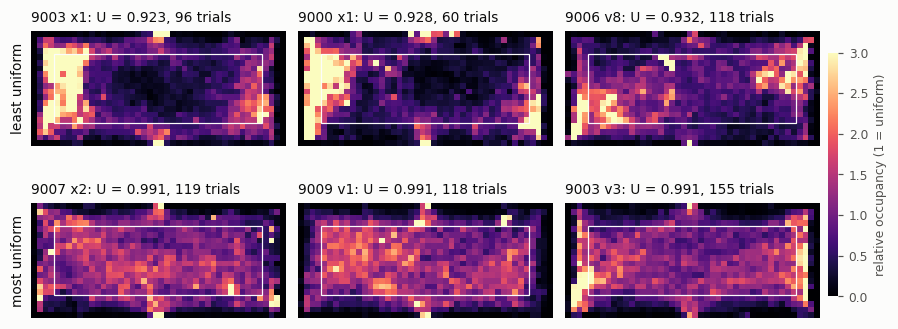

In [2]:
def density(maps):
    return maps / maps.sum(axis=(-2, -1), keepdims=True) * maps.shape[-2] * maps.shape[-1]

def show(ax, m, vmax=3):
    im = ax.imshow(m.T, origin='lower', extent=(0, cfg.FRAME_H, 0, cfg.FRAME_W), cmap='magma', vmin=0, vmax=vmax, interpolation='nearest')
    ax.add_patch(Rectangle((cfg.CELL_H, cfg.CELL_W), cfg.FRAME_H - 2 * cfg.CELL_H, cfg.FRAME_W - 2 * cfg.CELL_W, fill=False, edgecolor=PAPER, lw=0.8))
    ax.set(xticks=[], yticks=[])
    for side in ax.spines.values():
        side.set_visible(False)
    return im

order = ses.U_grid.sort_values().index
picks = list(order[:3]) + list(order[-3:])
fig, axes = plt.subplots(2, 3, figsize=(11, 3.6), gridspec_kw={'wspace': 0.05, 'hspace': 0.3})
for ax, i in zip(axes.flat, picks):
    r = ses.loc[i]
    im = show(ax, density(search_s[i]))
    ax.set_title(f"{r.mouse} {r.session}: U = {r.U_grid:.3f}, {r.trials} trials", fontsize=9, fontweight='normal')
axes[0, 0].set_ylabel('least uniform', color=INK); axes[1, 0].set_ylabel('most uniform', color=INK)
cb = fig.colorbar(im, ax=axes, shrink=0.8, pad=0.01, aspect=25); cb.set_label('relative occupancy (1 = uniform)', fontsize=8); cb.outline.set_visible(False)
plt.show()

## 2. Uniformity across sessions and mice

Each mouse's index session by session. Thin lines: mice. Thick line: mean across mice.

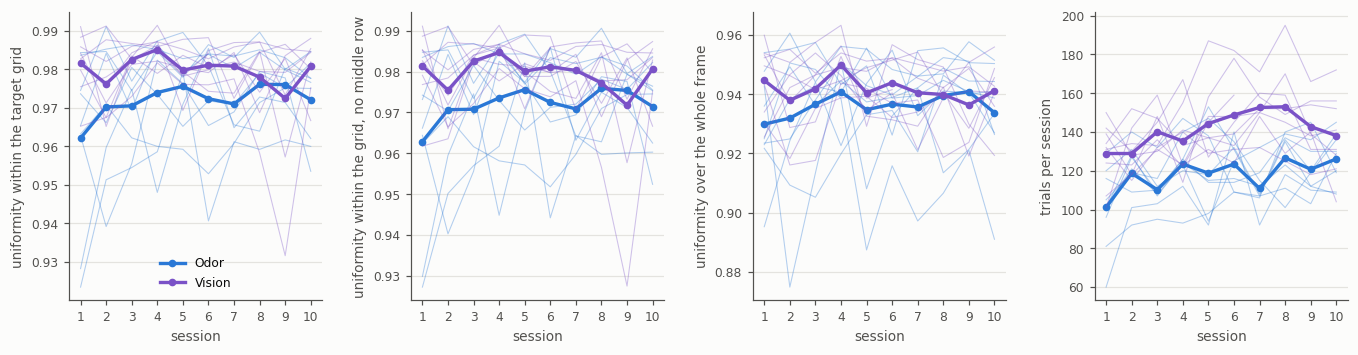

,Odor,Vision
variance of mouse means / variance of sessions,,
uniformity within the target grid,0.544,0.262
"uniformity within the grid, no middle row",0.518,0.275
uniformity over the whole frame,0.439,0.316
trials,0.212,0.329


In [3]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), gridspec_kw={'wspace': 0.35})
for ax, col in zip(axes, ['U_grid', 'U_ends', 'U_frame', 'trials']):
    for exp in EXPERIMENTS:
        s = ses[ses.experiment == exp]
        for _, g in s.groupby('mouse'):
            ax.plot(g.session_num, g[col], color=EXP_COLOR[exp], lw=0.7, alpha=0.35)
        mean = s.groupby('session_num')[col].mean()
        ax.plot(mean.index, mean, color=EXP_COLOR[exp], lw=2.2, marker='o', ms=4, label=EXP_LABEL[exp])
    ax.set(xlabel='session', ylabel=INDEX.get(col, 'trials per session'), xticks=range(1, 11))
    ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
axes[0].legend()
plt.show()

# how much of the variation is between mice
def share_between(col):
    return {EXP_LABEL[exp]: ses[ses.experiment == exp].groupby('mouse')[col].mean().var() / ses[ses.experiment == exp][col].var() for exp in EXPERIMENTS}
display(pd.DataFrame({INDEX.get(c, c): share_between(c) for c in [*INDEX, 'trials']}).T.rename_axis('variance of mouse means / variance of sessions'))

## 3. Regressing uniformity on trials per session

Four estimates of the slope (change in the index per 10 more trials), for each index and experiment, and for both experiments together:

- **pooled**: every session as an independent point. Mixes differences between mice with differences between a mouse's sessions.
- **between mice**: one point per mouse, its mean index against its mean trials.
- **within mouse**: each mouse's own least-squares slope across its sessions; the row gives the mean slope across mice, a t-test of that mean against zero, and how many mice have a positive slope. For both experiments together, a mouse's odor and vision sessions are centred separately before the fit, so the slope is within mouse and experiment.
- **within mouse, + session number**: the same, with session number as a second predictor in each mouse's fit.
- **within mouse, + search time**: with minutes of search per session as a second predictor. The search epoch includes the ITI and a session has a fixed length, so more trials leave less search time.

In [4]:
PER = 10        # slopes are per this many trials

def fit(y, X):
    """Least-squares coefficients of y on X (X without the intercept column)."""
    A = np.column_stack([np.ones(len(y)), X])
    return np.linalg.lstsq(A, y, rcond=None)[0][1:]

def centred(df, cols):
    """Each column minus its mean within mouse and experiment."""
    return df[cols] - df.groupby(['mouse', 'experiment'])[cols].transform('mean')

def regressions(df, col):
    out = {}
    r = sps.linregress(df.trials, df[col])
    out['pooled'] = dict(slope=r.slope * PER, p=r.pvalue, n=f'{len(df)} sessions', r=r.rvalue)
    means = df.groupby(['mouse', 'experiment'])[['trials', col]].mean().groupby('mouse').mean()
    r = sps.linregress(means.trials, means[col])
    out['between mice'] = dict(slope=r.slope * PER, p=r.pvalue, n=f'{len(means)} mice', r=r.rvalue)
    c = centred(df, ['trials', col, 'session_num', 'search_min'])
    for name, X in (('within mouse', ['trials']), ('within mouse, + session number', ['trials', 'session_num']),
                    ('within mouse, + search time', ['trials', 'search_min'])):
        slopes = pd.Series({m: fit(c.loc[g.index, col].to_numpy(), c.loc[g.index, X].to_numpy())[0] for m, g in df.groupby('mouse')}) * PER
        r_within = np.corrcoef(c.trials, c[col])[0, 1] if name == 'within mouse' else np.nan
        out[name] = dict(slope=slopes.mean(), sem=slopes.sem(), p=sps.ttest_1samp(slopes, 0).pvalue,
                         n=f'{int((slopes > 0).sum())}/{len(slopes)} mice positive', r=r_within)
    return pd.DataFrame(out).T[['slope', 'sem', 'p', 'r', 'n']]

GROUPS = {EXP_LABEL[e]: ses[ses.experiment == e] for e in EXPERIMENTS} | {'Both': ses}
results = pd.concat({(INDEX[col], g): regressions(df, col) for col in INDEX for g, df in GROUPS.items()})
results.index.names = ['index', 'sessions', 'estimate']
results.style.format({'slope': '{:+.4f}', 'sem': '{:.4f}', 'p': '{:.4f}', 'r': '{:.2f}'}, na_rep='')

**The within-mouse relation, drawn.** Each session's index and trial count minus its mouse's mean for that experiment, so every mouse is centred on zero. Thin lines: each mouse's own fit. Thick line: the mean within-mouse slope.

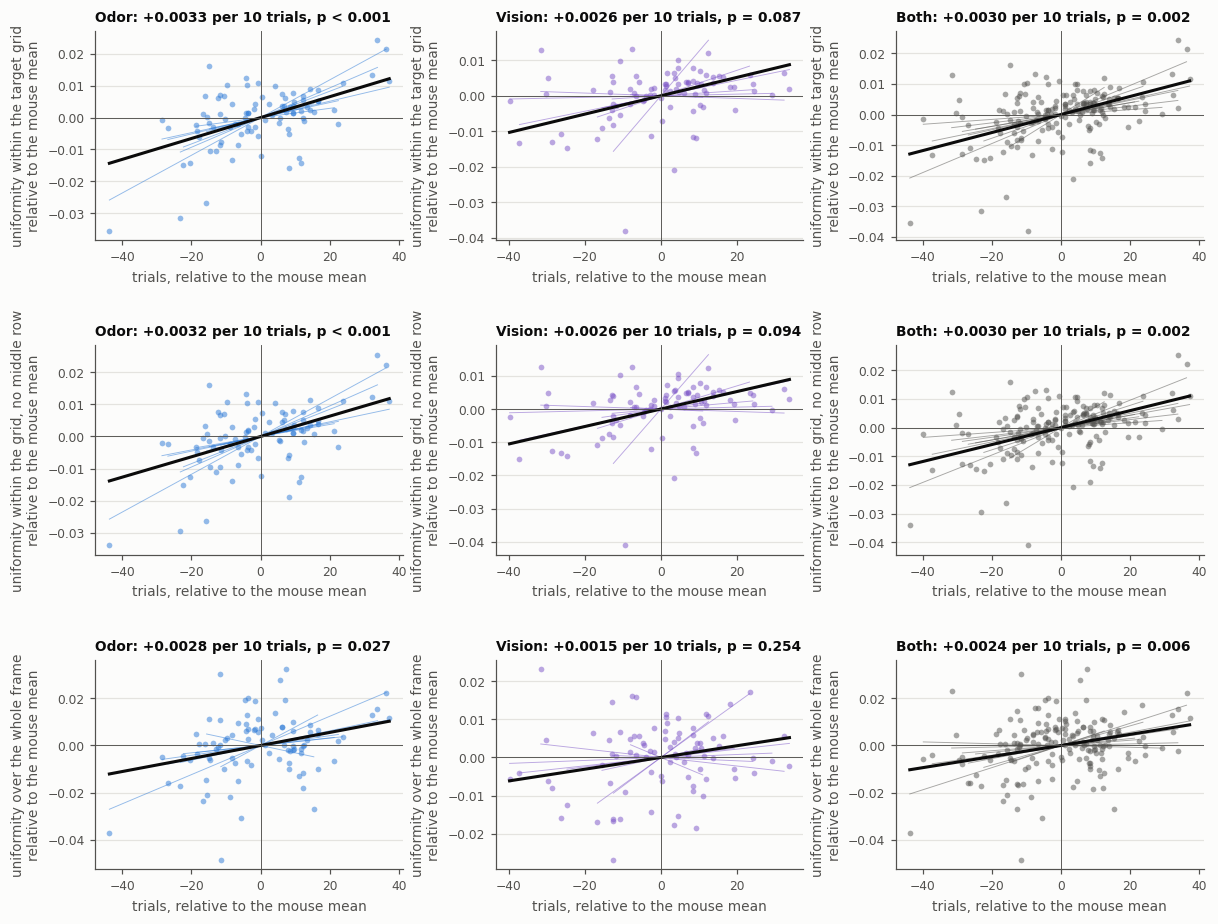

In [5]:
fig, axes = plt.subplots(len(INDEX), 3, figsize=(13, 3.3 * len(INDEX)), gridspec_kw={'wspace': 0.3, 'hspace': 0.5})
for row, col in zip(axes, INDEX):
    for ax, (g, df) in zip(row, GROUPS.items()):
        c = centred(df, ['trials', col])
        color = EXP_COLOR.get(g.lower(), MUTED)
        ax.scatter(c.trials, c[col], s=14, color=color, alpha=0.5, lw=0)
        xs = np.array([c.trials.min(), c.trials.max()])
        slopes = []
        for m, gm in df.groupby('mouse'):
            b = fit(c.loc[gm.index, col].to_numpy(), c.loc[gm.index, ['trials']].to_numpy())[0]
            slopes.append(b)
            span = np.array([c.loc[gm.index, 'trials'].min(), c.loc[gm.index, 'trials'].max()])
            ax.plot(span, b * span, color=color, lw=0.6, alpha=0.5)
        ax.plot(xs, np.mean(slopes) * xs, color=INK, lw=2)
        ax.axhline(0, color=MUTED, lw=0.6); ax.axvline(0, color=MUTED, lw=0.6)
        res = results.loc[(INDEX[col], g, 'within mouse')]
        ax.set_title(f"{g}: {res.slope:+.4f} per {PER} trials, {'p < 0.001' if res.p < 0.001 else f'p = {res.p:.3f}'}", fontsize=9)
        ax.set(xlabel='trials, relative to the mouse mean', ylabel=f'{INDEX[col]}\nrelative to the mouse mean')
        ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
plt.show()

**Between mice.** Each mouse's mean index against its mean trials per session, one point per mouse and experiment.

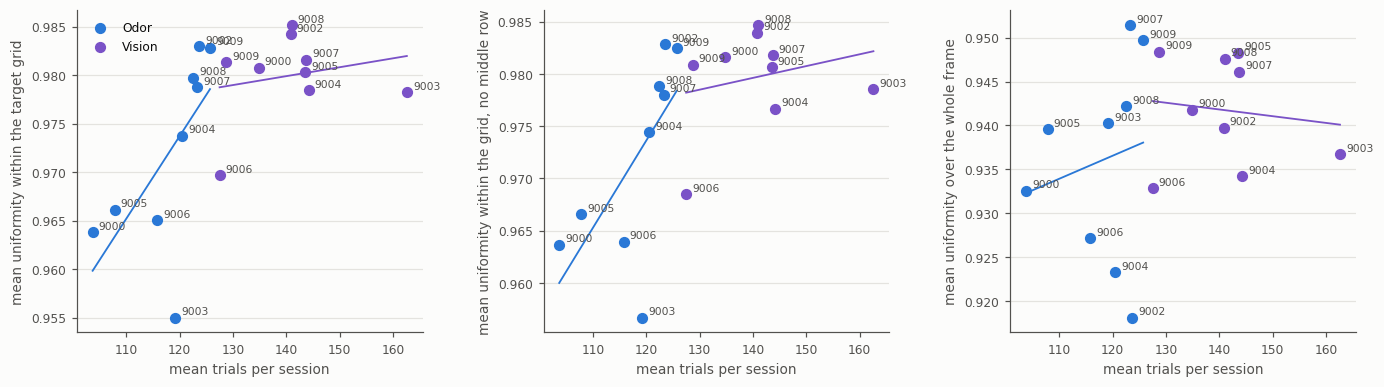

In [6]:
fig, axes = plt.subplots(1, len(INDEX), figsize=(15, 3.8), gridspec_kw={'wspace': 0.35})
for ax, col in zip(axes, INDEX):
    for exp in EXPERIMENTS:
        means = ses[ses.experiment == exp].groupby('mouse')[['trials', col]].mean()
        ax.scatter(means.trials, means[col], s=40, color=EXP_COLOR[exp], label=EXP_LABEL[exp], zorder=3)
        for m, r in means.iterrows():
            ax.annotate(m, (r.trials, r[col]), xytext=(4, 2), textcoords='offset points', fontsize=7, color=MUTED)
        b = sps.linregress(means.trials, means[col])
        xs = np.array([means.trials.min(), means.trials.max()])
        ax.plot(xs, b.intercept + b.slope * xs, color=EXP_COLOR[exp], lw=1.2)
    ax.set(xlabel='mean trials per session', ylabel=f'mean {INDEX[col]}')
    ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
axes[0].legend()
plt.show()

## 4. What else moves with trials per session

Uniformity could follow trials per session for reasons other than search strategy. Within-mouse correlations (session values centred on the mouse's mean for that experiment) between trials, the indexes, the share of search time outside the target grid and in its middle row, minutes of search time per session, and session number.

In [7]:
COLS = ['trials', *INDEX, 'outside_grid', 'mid_row', 'search_min', 'session_num']
corr = pd.concat({EXP_LABEL[e]: centred(ses[ses.experiment == e], COLS).corr().loc[['trials', 'U_grid'], COLS] for e in EXPERIMENTS})
corr.style.format('{:.2f}')

**Search time and trials are two sides of one number.** A session has a fixed length and the search epoch includes the ITI, so more trials leave fewer minutes of search (within-mouse r = -0.55 in odor, -0.34 in vision). Adding search time to the fit therefore takes away much of the trials effect (odor: +0.0033 to +0.0020 per 10 trials, p = 0.14) without saying which of the two matters. It is not a sampling artifact, though: less search time means fewer frames, which would if anything *lower* an entropy estimate, yet the sessions with less search time are the more uniform ones (r = -0.44 in odor).

**Not the middle row.** Leaving the middle row out of the index changes nothing (r with the full grid index 0.99 in odor, 1.00 in vision), so the relation is not the extra time spent leaving the ports.

## Summary

**The index.** Within the target grid, search time is spread close to evenly in every session: the index runs from 0.92 to 0.99, with a mean of 0.972 in odor and 0.980 in vision. The least uniform sessions are the ones where the nose sits against the low-y end wall. The differences are small in absolute terms but consistent, and the regressions below are best read through the correlations (r) and the counts of mice.

**Within a mouse, sessions with more trials have more uniform search.**
- *Odor:* +0.0033 per 10 trials (within-mouse r = 0.55), positive in 9/9 mice, p = 0.0001. A session 20 trials above the mouse's average is about half a standard deviation more uniform.
- *Vision:* the same direction, weaker: +0.0026 per 10 trials (r = 0.29), 7/9 mice, p = 0.09.
- *Both together:* +0.0030 per 10 trials, 9/9 mice, p = 0.002.
- Controlling for session number barely changes this (odor +0.0030, 9/9 mice), so it is not just that both improve with experience.

**Between mice the picture is weaker.** In odor, mice with more trials per session also search more evenly (r = 0.65 across 9 mice, p = 0.06). In vision there is no relation (r = 0.21, p = 0.58).

**Over the whole frame** the relation is weaker (odor +0.0028 per 10 trials, 8/9 mice, p = 0.03; vision not significant). The whole-frame index also counts time outside the grid, which falls in sessions with more trials (within-mouse r = -0.48 in odor), so the two effects partly cancel.

**Reading the results.**
- The regression does not give a direction. Searching evenly may find targets sooner, or a session that goes well may simply have shorter searches that never settle into one place.
- Trials and search minutes cannot be separated (see above).
- A search ends at its target, and targets are spread over the grid's ends, so more searches spread more end-points over the grid. This could raise within-grid uniformity by itself and is not tested here.
- p-values are unadjusted. Three indexes, three session groups and four estimates are shown, and they are far from independent.